# 01 Exploration: data and tokenization (tasks 3–4)
Important: run `python -m src.prepare_data` before

In [1]:
import os, sys; os.chdir('..'); sys.path.insert(0, '.')
from datasets import load_from_disk
from src.tokenize_data import get_tokenizer, show_tokens
from src.utils import load_config
cfg = load_config()
ds = load_from_disk('data/domain'); ds

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 9600
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 1200
    })
    test: Dataset({
        features: ['text'],
        num_rows: 1200
    })
})

In [2]:
tok = get_tokenizer(cfg['model']['name'])
sample = ds['train'][0]['text'][:300]
print(sample)
print(show_tokens(sample, tok))

This movie succeeds at being one of the most unique movies you've seen. However this comes from the fact that you can't make heads or tails of this mess. It almost seems as a series of challenges set up to determine whether or not you are willing to walk out of the movie and give up the money you ju
['This', ' movie', ' succeeds', ' at', ' being', ' one', ' of', ' the', ' most', ' unique', ' movies', ' you', "'ve", ' seen', '.', ' However', ' this', ' comes', ' from', ' the', ' fact', ' that', ' you', ' can', "'t", ' make', ' heads', ' or', ' tails', ' of', ' this', ' mess', '.', ' It', ' almost', ' seems', ' as', ' a', ' series', ' of', ' challenges', ' set', ' up', ' to', ' determine', ' whether', ' or', ' not', ' you', ' are', ' willing', ' to', ' walk', ' out', ' of', ' the', ' movie', ' and', ' give', ' up', ' the', ' money', ' you', ' ju']


Token indices sequence length is longer than the specified maximum sequence length for this model (1248 > 1024). Running this sequence through the model will result in indexing errors


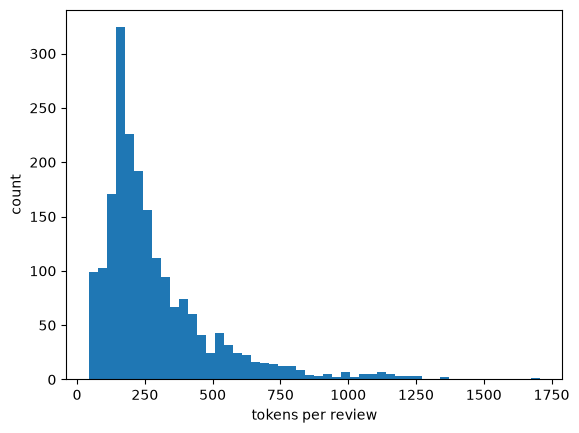

mean 288.1485 median 220.5


In [3]:
# Token length distribution per document
import matplotlib.pyplot as plt
lens = [len(tok(t)['input_ids']) for t in ds['train'].select(range(2000))['text']]
plt.hist(lens, bins=50); plt.xlabel('tokens per review'); plt.ylabel('count'); plt.show()
import numpy as np; print('mean', np.mean(lens), 'median', np.median(lens))

In [4]:
# Qualitative: how does GPT2 BPE split domain words, names, Lithuanian text?
for s in ['cinematography', 'Tarantino', 'overacted', 'Šiandien labai graži diena']:
    print(s, '->', show_tokens(s, tok))

cinematography -> ['c', 'inem', 'atography']
Tarantino -> ['T', 'arant', 'ino']
overacted -> ['over', 'acted']
Šiandien labai graži diena -> ['�', '�', 'i', 'and', 'ien', ' lab', 'ai', ' gra', '�', '�', 'i', ' d', 'ien', 'a']


## Plot training curves (task 8, 13)

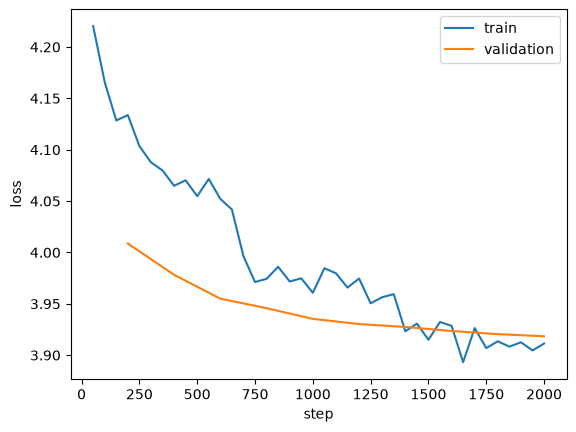

In [5]:
import json
log = json.load(open('outputs/full/log_history.json'))
tr = [(r['step'], r['loss']) for r in log if 'loss' in r]
va = [(r['step'], r['eval_loss']) for r in log if 'eval_loss' in r]
plt.plot(*zip(*tr), label='train'); plt.plot(*zip(*va), label='validation')
plt.xlabel('step'); plt.ylabel('loss'); plt.legend(); plt.show()

In [ ]:
import json
log = json.load(open('outputs/full/log_history.json'))
tr = [(r['step'], r['loss']) for r in log if 'loss' in r]
va = [(r['step'], r['eval_loss']) for r in log if 'eval_loss' in r]
plt.plot(*zip(*tr), label='train'); plt.plot(*zip(*va), label='validation')
plt.xlabel('step'); plt.ylabel('loss'); plt.legend(); plt.show()